# Milestone 2

### Data Audit
Shape -> (114000, 5)  
Columns -> 'danceability', 'energy', 'loudness', 'tempo', 'popularity'  
dtypes ->    
danceability    float64  
energy          float64  
loudness        float64  
tempo           float64  
popularity        int64  

Outliers -> box plot using seaborn and matplotlib

In [1]:
import pandas as pd
df = pd.read_csv("dataset.csv")
keep = ["danceability", "energy", "loudness", "tempo", "popularity"]
df = df[keep]
df.head

<bound method NDFrame.head of         danceability  energy  loudness    tempo  popularity
0              0.676  0.4610    -6.746   87.917          73
1              0.420  0.1660   -17.235   77.489          55
2              0.438  0.3590    -9.734   76.332          57
3              0.266  0.0596   -18.515  181.740          71
4              0.618  0.4430    -9.681  119.949          82
...              ...     ...       ...      ...         ...
113995         0.172  0.2350   -16.393  125.995          21
113996         0.174  0.1170   -18.318   85.239          22
113997         0.629  0.3290   -10.895  132.378          22
113998         0.587  0.5060   -10.889  135.960          41
113999         0.526  0.4870   -10.204   79.198          22

[114000 rows x 5 columns]>

Shape

In [2]:
print(df.shape)

(114000, 5)


In [3]:
print(df.columns)

Index(['danceability', 'energy', 'loudness', 'tempo', 'popularity'], dtype='str')


In [4]:
print(df.dtypes)

danceability    float64
energy          float64
loudness        float64
tempo           float64
popularity        int64
dtype: object


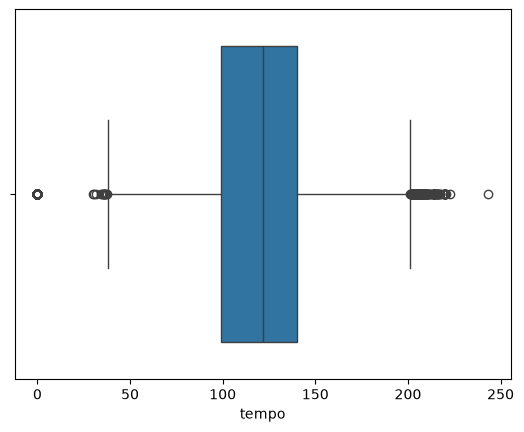

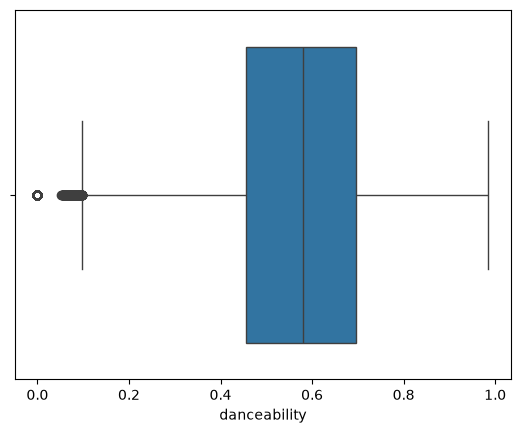

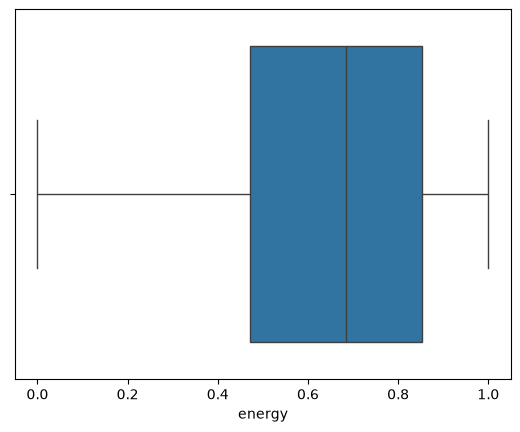

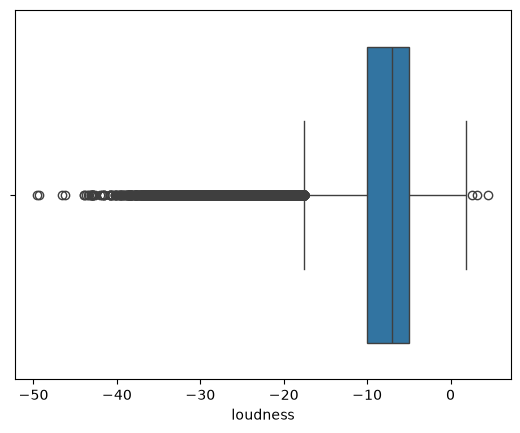

In [5]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x = df ["tempo"])
plt.show()
sns.boxplot(x = df ["danceability"])
plt.show()
sns.boxplot(x = df ["energy"])
plt.show()
sns.boxplot(x = df ["loudness"])
plt.show()


### Clean Up
Remove Duplicates
Remove Data with missing values

In [23]:
df = df.drop_duplicates();

In [7]:
print(df.shape)

(86703, 5)


In [8]:
df.isna().sum()

danceability    0
energy          0
loudness        0
tempo           0
popularity      0
dtype: int64

In [9]:
df = df.dropna()

In [10]:
print(df.shape)


(86703, 5)


In [11]:
df_cleaned = df[(df['tempo'] >= 40) & (df['tempo'] <= 200)]
df_cleaned = df[(df['danceability'] >= .15) & (df['danceability'] <= 1)]
df_cleaned = df[(df['energy'] >= 0) & (df['energy'] <= 1)]
df_cleaned = df[(df['loudness'] >= -20) & (df['loudness'] <= 0)]
print("Cleaned Data:\n", df_cleaned)
    

Cleaned Data:
         danceability  energy  loudness    tempo  popularity
0              0.676  0.4610    -6.746   87.917          73
1              0.420  0.1660   -17.235   77.489          55
2              0.438  0.3590    -9.734   76.332          57
3              0.266  0.0596   -18.515  181.740          71
4              0.618  0.4430    -9.681  119.949          82
...              ...     ...       ...      ...         ...
113995         0.172  0.2350   -16.393  125.995          21
113996         0.174  0.1170   -18.318   85.239          22
113997         0.629  0.3290   -10.895  132.378          22
113998         0.587  0.5060   -10.889  135.960          41
113999         0.526  0.4870   -10.204   79.198          22

[82979 rows x 5 columns]


### Data Split
80/20 split, random state 42, stratify y  
no scaling done since using tree

In [12]:
df_cleaned.head()

,danceability,energy,loudness,tempo,popularity
0,0.676,0.4610,-6.746,87.917,73
1,0.420,0.1660,-17.235,77.489,55
2,0.438,0.3590,-9.734,76.332,57
3,0.266,0.0596,-18.515,181.740,71
4,0.618,0.4430,-9.681,119.949,82


In [13]:
threshold = 50
df_cleaned["is_popular"] = (df_cleaned["popularity"] >= threshold).astype(int) 

In [26]:
print(df_cleaned.shape)

(82979, 6)


In [15]:
from sklearn.model_selection import train_test_split
X = df_cleaned.iloc[:, 0:4]
y = df_cleaned.iloc[:, 5]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = .2, random_state = 42, stratify = y
)

In [16]:
print(df_cleaned.columns.tolist())

['danceability', 'energy', 'loudness', 'tempo', 'popularity', 'is_popular']


## Run Model

In [42]:
#DUMMY CLASSIFIER
from sklearn.metrics import accuracy_score

from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy = "stratified", random_state = 42)
dummy.fit(X_train, y_train)
yd_pred = dummy.predict(X_test)
print(accuracy_score(y_test, yd_pred))

0.6328633405639913


In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate, StratifiedKFold


#drop popularity
#df = df.drop(columns = ['popularity'])


tree = make_pipeline(
    
    DecisionTreeClassifier(
        max_depth = 4,
        min_samples_leaf = 10,
        random_state = 42,
        class_weight="balanced"

    )
)
cv = StratifiedKFold(n_splits = 7, shuffle = True, random_state = 42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
scores = cross_validate(tree, X_train, y_train, scoring=scoring, cv = cv)

tree.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('decisiontreeclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['danceability','energy','loudness','tempo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an int

In [35]:
#treat as classification problem
#think of converting one of the rows 
#show distribution of the classes
#show class imbalance
#drop outliers
#scaling only on trained data
#cross valitdation
#auc, proposed metrics, accuracy, recall, precsion, f1



## Analysis


In [36]:
y_pred = tree.predict(X_test)

In [37]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

[[6106 6401]
 [1516 2573]]


In [38]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test, y_pred))

0.5229573391178597


In [39]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.49      0.61     12507
           1       0.29      0.63      0.39      4089

    accuracy                           0.52     16596
   macro avg       0.54      0.56      0.50     16596
weighted avg       0.67      0.52      0.55     16596

